# Cumulative Return vs. Benchmark

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Shows the growth of an investment (for example, 10,000 invested at the start) for a fund and its benchmark on one log-scaled axis. On a log scale equal vertical distances mean equal percentage changes, so a 50% rise looks the same in 2015 as in 2024 and the slopes of the two lines compare growth rates directly.

## When to use

- Compare long-run performance of a fund, strategy or stock against a benchmark
- Show compounding over many years, where a linear axis would flatten the early period
- Introduce a performance report before drilling into drawdowns and rolling metrics

## Avoid when

- The horizon is short (under a year) and percentage moves are small (a linear axis is fine)
- Comparing many funds at once (use a risk-return scatter or small multiples)
- The audience is unfamiliar with log axes and there is no space to explain them

## Alternatives

- Indexed line chart (rebased to 100) on a linear axis
- Annual returns bar chart
- Risk-return scatter for many funds

## Design tips

- State the scale ("log scale") in the axis label
- Label the end of each line with its final value and CAGR instead of using a legend box alone
- Show the benchmark in a recessive color so the fund reads as the subject

## Example

Simulated daily total returns for a fund and its benchmark, 2015–2024 (including a 2020-style crash and a 2022-style bear market), shown as the growth of 10,000. Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.ticker import FuncFormatter, LogLocator

### Data

In [2]:
# Simulated daily simple returns: fat-tailed market (Student-t, 4 df) plus a fund with beta 0.9.
rng = np.random.default_rng(21)
dates = pd.bdate_range("2015-01-01", "2024-12-31")
n = len(dates)
mkt = 0.00045 + rng.standard_t(4, n) * 0.0095 / np.sqrt(2)
crash = (dates >= "2020-02-20") & (dates <= "2020-03-23")
mkt[crash] -= 0.012
mkt[(dates >= "2022-01-01") & (dates <= "2022-10-15")] -= 0.0011
fund = 0.00024 + 0.9 * mkt + rng.normal(0, 0.004, n)
fund[0] = mkt[0] = 0.0  # the first date is the start: both series begin at exactly 10,000
prices = 10_000 * (1 + pd.DataFrame({"Fund": fund, "Benchmark": mkt}, index=dates)).cumprod()
freq = 252  # observations per year, used for CAGR
prices.tail()

,Fund,Benchmark
2024-12-25,29177.402501,25094.866386
2024-12-26,29831.878133,25707.055420
2024-12-27,29354.904232,25274.172943
2024-12-30,29350.224800,25223.044789
2024-12-31,29375.049004,25151.946003


### Plot

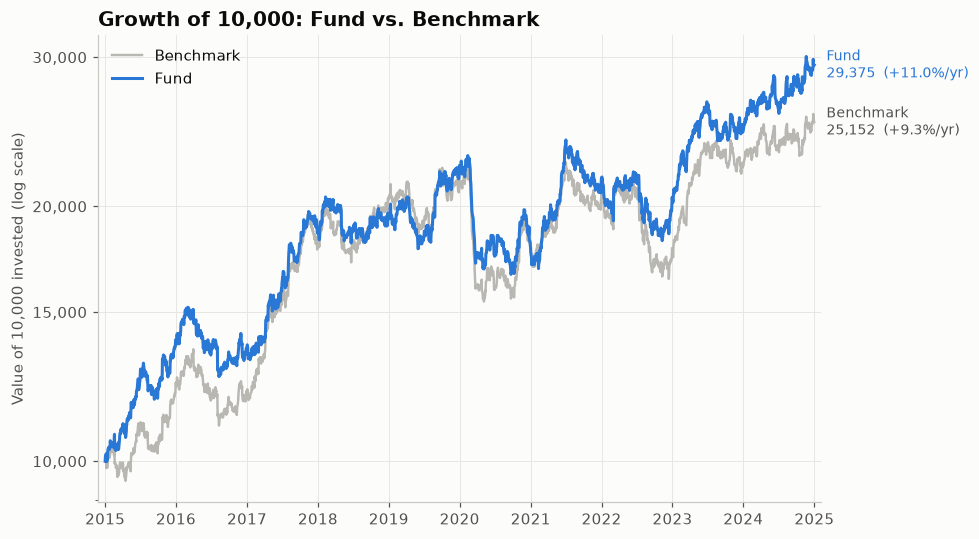

In [3]:
fund_name, bench_name = prices.columns[:2]
years = (len(prices) - 1) / freq  # n prices span n - 1 return periods
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(prices.index, prices[bench_name], color=GRAY, linewidth=1.6, label=bench_name)
ax.plot(prices.index, prices[fund_name], color=PALETTE[0], linewidth=2, label=fund_name)
ax.set_yscale("log")
ax.yaxis.set_major_locator(LogLocator(base=10, subs=[1, 1.5, 2, 3, 5, 7]))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
for name, color in [(fund_name, PALETTE[0]), (bench_name, "#52514e")]:
    end = prices[name].iloc[-1]
    cagr = (end / prices[name].iloc[0]) ** (1 / years) - 1
    ax.annotate(f"{name}\n{end:,.0f}  ({cagr:+.1%}/yr)", (prices.index[-1], end),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=color)
ax.set_ylabel("Value of 10,000 invested (log scale)")
ax.set_title(f"Growth of 10,000: {fund_name} vs. {bench_name}")
ax.legend(loc="upper left")
ax.margins(x=0.01)
fig.tight_layout()
plt.show()

## How to read it

Both lines start at 10,000. Where the blue line is steeper than the gray line the fund was compounding faster. The final values and compound annual growth rates (CAGR) are labelled at the right edge.

## Try it with real data

**Source:** plotly.express.data.stocks() — weekly AAPL vs an equal-weight basket of 6 large tech stocks, 2018–2019

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
import plotly.express as px
stocks = px.data.stocks().set_index("date")
stocks.index = pd.to_datetime(stocks.index)
basket = stocks.pct_change().mean(axis=1).fillna(0).add(1).cumprod()  # equal-weight, rebalanced weekly
prices = 10_000 * pd.DataFrame({"AAPL": stocks["AAPL"], "Tech basket": basket})
freq = 52
prices.tail()

,AAPL,Tech basket
date,,
2019-12-02,15469.142343,14428.234881
2019-12-09,15722.856800,14385.233723
2019-12-16,15968.000114,14964.220641
2019-12-23,16559.999314,15165.728853
2019-12-30,16779.999657,15044.770973


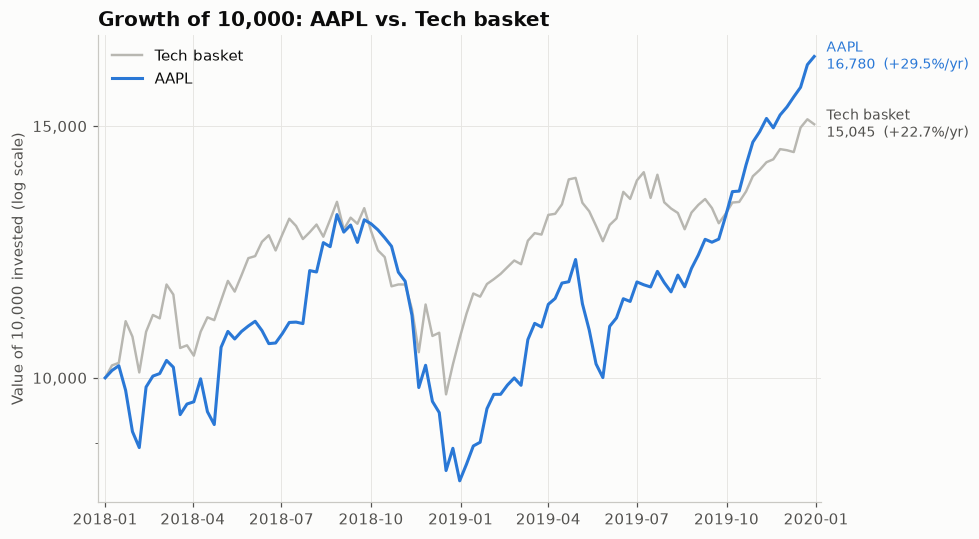

In [5]:
fund_name, bench_name = prices.columns[:2]
years = (len(prices) - 1) / freq  # n prices span n - 1 return periods
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(prices.index, prices[bench_name], color=GRAY, linewidth=1.6, label=bench_name)
ax.plot(prices.index, prices[fund_name], color=PALETTE[0], linewidth=2, label=fund_name)
ax.set_yscale("log")
ax.yaxis.set_major_locator(LogLocator(base=10, subs=[1, 1.5, 2, 3, 5, 7]))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
for name, color in [(fund_name, PALETTE[0]), (bench_name, "#52514e")]:
    end = prices[name].iloc[-1]
    cagr = (end / prices[name].iloc[0]) ** (1 / years) - 1
    ax.annotate(f"{name}\n{end:,.0f}  ({cagr:+.1%}/yr)", (prices.index[-1], end),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=color)
ax.set_ylabel("Value of 10,000 invested (log scale)")
ax.set_title(f"Growth of 10,000: {fund_name} vs. {bench_name}")
ax.legend(loc="upper left")
ax.margins(x=0.01)
fig.tight_layout()
plt.show()

---
Standalone script: [`cumulative_return_benchmark.py`](cumulative_return_benchmark.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)